# 17. Introduction to Image Segmentation

**Dataset note:**  Displays an image from the local CIFAR-10 dataset. CIFAR-10 contains image-level class labels, but no pixel masks or segmentation annotations. The small masks below are made-up examples, not labels for the CIFAR-10 image.

## 1. What is image segmentation?

**Explanation:** Image segmentation divides an image into meaningful regions by assigning labels to pixels. Unlike image classification, it shows which parts of the image belong to an object or region.

**Example:** In a road image, pixels could be labeled as road, car, person, or background.

In [1]:
pixel_classes = ["background", "road", "car", "person"]
print("Possible labels for pixels:", pixel_classes)

Possible labels for pixels: ['background', 'road', 'car', 'person']


**Interpretation:** Segmentation describes the contents and locations of regions throughout the image, not only one label for the whole image.

## 2. Pixel-level classification

**Explanation:** Pixel-level classification gives each pixel a class label. A segmentation map stores these labels in a grid that lines up with the image.

**Example:** `0` can mean background and `1` can mean object.

In [2]:
pixel_labels = [[0, 0, 0], [0, 1, 1], [0, 1, 1]]
label_names = {0: "background", 1: "object"}
print("Pixel label map:", pixel_labels)
print("Label meanings:", label_names)

Pixel label map: [[0, 0, 0], [0, 1, 1], [0, 1, 1]]
Label meanings: {0: 'background', 1: 'object'}


**Interpretation:** Each number corresponds to a pixel. The lower-right pixels are labeled as the object; the others are background. This tiny grid is only an example.

## 3. Masks

**Explanation:** A mask is an image-shaped map that marks which pixels belong to a class or object. A binary mask commonly uses `1` for selected pixels and `0` for everything else.

**Example:** Make a tiny mask that marks a square object.

In [3]:
object_mask = [[0, 0, 0, 0], [0, 1, 1, 0], [0, 1, 1, 0], [0, 0, 0, 0]]
for row in object_mask:
    print(row)

[0, 0, 0, 0]
[0, 1, 1, 0]
[0, 1, 1, 0]
[0, 0, 0, 0]


**Interpretation:** The `1` values mark the object pixels and trace its area more closely than a rectangle. This is a simple, hand-written mask.

## 4. Semantic segmentation

**Explanation:** Semantic segmentation assigns a class to every pixel. Pixels belonging to the same class receive the same label, even if they come from different objects. For example, two cars are both labeled `car`.

**Example:** A map labels pixels as background (`0`) or car (`1`).

In [4]:
semantic_map = [[0, 0, 0, 0], [1, 1, 0, 1], [1, 1, 0, 1]]
print("0 = background, 1 = car")
for row in semantic_map:
    print(row)

0 = background, 1 = car
[0, 0, 0, 0]
[1, 1, 0, 1]
[1, 1, 0, 1]


**Interpretation:** Both car-shaped regions use label `1`. The map tells us the class of each pixel, but not which car instance it belongs to.

## 5. Instance segmentation

**Explanation:** Instance segmentation gives each individual object its own mask and identity. Two objects of the same class, such as two cars, are kept separate.

**Example:** Use `1` for one car and `2` for another.

In [5]:
instance_map = [[0, 0, 0, 0], [1, 1, 0, 2], [1, 1, 0, 2]]
print("0 = background, 1 = first car, 2 = second car")
for row in instance_map:
    print(row)

0 = background, 1 = first car, 2 = second car
[0, 0, 0, 0]
[1, 1, 0, 2]
[1, 1, 0, 2]


**Interpretation:** The two cars have separate IDs even though they share the same class. Each ID corresponds to an individual object's mask.

## 6. Panoptic segmentation

**Explanation:** Panoptic segmentation combines semantic and instance segmentation. It labels the background and broad regions, while also keeping individual countable objects separate. For example, road pixels share a class, while each car has its own identity.

**Example:** A simplified map uses `0` for road, `1` for one car, and `2` for another.

In [6]:
panoptic_map = [[0, 0, 0, 0], [1, 1, 0, 2], [1, 1, 0, 2]]
labels = {0: "road", 1: "car instance 1", 2: "car instance 2"}
print("Panoptic labels:", labels)
for row in panoptic_map:
    print(row)

Panoptic labels: {0: 'road', 1: 'car instance 1', 2: 'car instance 2'}
[0, 0, 0, 0]
[1, 1, 0, 2]
[1, 1, 0, 2]


**Interpretation:** The map labels the road region and keeps the two cars distinct. This combines class information with object-instance identity.

## 7. Bounding boxes vs. masks

**Explanation:** A bounding box surrounds an object with a rectangle. A mask marks the object's pixels and can follow its shape. Boxes are simpler; masks give more precise outlines.

**Example:** One object can be represented by a rectangle `[x_min, y_min, x_max, y_max]` or by a grid of pixel labels.

In [7]:
object_box = [1, 1, 3, 3]
object_mask = [[0, 0, 0, 0], [0, 1, 1, 0], [0, 1, 0, 0], [0, 0, 0, 0]]
print("Box:", object_box)
print("Mask:")
for row in object_mask:
    print(row)

Box: [1, 1, 3, 3]
Mask:
[0, 0, 0, 0]
[0, 1, 1, 0]
[0, 1, 0, 0]
[0, 0, 0, 0]


**Interpretation:** The box covers a rectangular area around the object, including some background. The mask marks only the example object pixels.

## 8. FCN (Fully Convolutional Network)

**Explanation:** An FCN uses convolutional layers to turn an image into a grid of class scores, then produces a pixel-label map. Unlike a basic image classifier, it preserves spatial layout in its output.

**Application:** FCNs are an early, general approach to semantic segmentation, such as labeling road and background pixels in a street scene.

**Conceptual example:**

In [8]:
fcn_idea = "image -> convolutional layers -> pixel class map"
print(fcn_idea)

image -> convolutional layers -> pixel class map


**Interpretation:** The FCN produces a class for image locations rather than only one class for the entire image. This is a conceptual flow, not an implementation.

## 9. U-Net

**Explanation:** U-Net has a downsampling path that learns context and an upsampling path that restores spatial detail. Connections between matching stages help pass fine image details to the output.

**Application:** U-Net is widely used for biomedical images, for example outlining cells or organs.

**Conceptual example:**

In [9]:
unet_idea = "image -> compress context -> restore detail -> mask"
print(unet_idea)

image -> compress context -> restore detail -> mask


**Interpretation:** U-Net combines broad context with local detail to produce a pixel mask. The line is a simplified description, not a model implementation.

## 10. Mask R-CNN

**Explanation:** Mask R-CNN extends object detection by predicting a separate pixel mask for each detected object, in addition to its class and bounding box.

**Application:** It is useful when individual object outlines matter, such as separating each person or vehicle in a scene.

**Conceptual example:**

In [10]:
mask_r_cnn_output = {"class": "person", "box": [2, 1, 6, 7], "mask": "pixels of this person"}
print(mask_r_cnn_output)

{'class': 'person', 'box': [2, 1, 6, 7], 'mask': 'pixels of this person'}


**Interpretation:** For an object, the example output includes what it is, where its box is, and which pixels belong to it. The mask value is described in words rather than generated by a model.

## 11. View an image from the local dataset

**Explanation:** We can inspect a CIFAR-10 image and its image-level class label, but the dataset has no masks. Therefore this image is shown without pretending that a segmentation mask is available.

**Example code:**

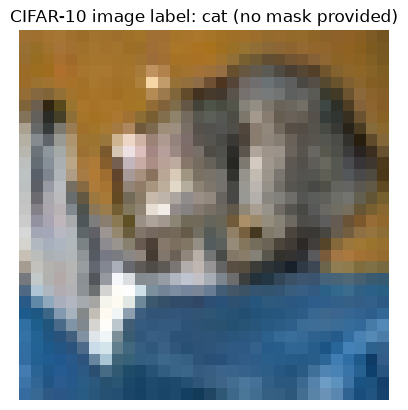

In [11]:
from pathlib import Path
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10

data_path = Path("data")
if not (data_path / "cifar-10-batches-py").is_dir():
    raise FileNotFoundError("Local CIFAR-10 data is missing from the data folder.")
test_data = CIFAR10(root=data_path, train=False, download=False)
image, label = test_data[0]
plt.imshow(image)
plt.title(f"CIFAR-10 image label: {test_data.classes[label]} (no mask provided)")
plt.axis("off");

**Interpretation:** The dataset tells us the image class, but not which pixels belong to the object. Training segmentation models needs images paired with mask annotations.

## Summary

- **Semantic segmentation:** label pixels by class; same-class objects share a label.
- **Instance segmentation:** give each object its own mask and identity.
- **Panoptic segmentation:** combine class-level regions with separate identities for countable objects.
- **FCN, U-Net, and Mask R-CNN** are different architecture approaches; each produces or uses spatial information for segmentation.

Choose boxes when a rough object location is enough; choose masks when the object's pixel outline matters. This notebook explains the ideas without implementing or training these architectures.